# Semana 6 · Segmentación de clientes (laboratorio de Orange en Python)
**Pregunta de negocio:** ¿a qué grupos de clientes se les habla distinto, y cuánto vale cada grupo?

Este notebook repite los cinco pasos del laboratorio de Orange con scikit-learn: mismas variables, mismas técnicas y mismos parámetros. Datos: `clientes_retail.csv` (real, 2,205 clientes de un retailer de alimentos) y `formas_lunas.csv` (sintético).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

GREEN, GOLD = "#00704A", "#C8A24A"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

def leer(ruta):
    d = pd.read_csv(ruta)
    d.columns = [c.split("#")[-1] for c in d.columns]
    return d

df = leer("clientes_retail.csv")
print(df.shape, "| valores faltantes:", int(df.isna().sum().sum()))
df.head(3)

(2205, 23) | valores faltantes: 0


,id_cliente,ingreso_anual,edad,hijos_pequenos,hijos_adolescentes,dias_como_cliente,recencia_dias,gasto_vinos,gasto_frutas,gasto_carnes,...,gasto_total,compras_oferta,compras_web,compras_catalogo,compras_tienda,visitas_web_mes,campanas_aceptadas,educacion,estado_civil,respondio_ultima_campana
0,1,58138,63,0,0,2822,58,635,88,546,...,1529,3,8,10,4,7,0,Licenciatura,Soltero,1
1,2,46344,66,1,1,2272,38,11,1,6,...,21,2,1,1,2,5,0,Licenciatura,Soltero,0
2,3,71613,55,0,0,2471,26,426,49,127,...,734,1,8,2,10,4,0,Licenciatura,Union_libre,0


## Parte 0 · Distancia a mano: por qué estandarizar

In [2]:
A, B, Cc = np.array([30000, 3]), np.array([32000, 15]), np.array([60000, 4])
sd = np.array([20000, 5])
dist = lambda p, q, s=1: np.sqrt((((p - q) / s) ** 2).sum())
pd.DataFrame({"Sin estandarizar": [dist(A, B), dist(A, Cc)],
              "Estandarizado": [dist(A, B, sd), dist(A, Cc, sd)]},
             index=["A–B", "A–C"]).round(2)

,Sin estandarizar,Estandarizado
A–B,2000.04,2.40
A–C,30000.00,1.51


**Respuesta.** Sin estandarizar, B queda a ≈2,000 de A y C a ≈30,000, porque el ingreso (decenas de miles) domina la distancia y las visitas casi no cuentan. Estandarizadas, A–C es ≈1.51 y A–B ≈2.40: C pasa a ser el más cercano, porque ahora B pesa por visitar la web 5 veces más. Antes de segmentar hay que poner las variables en la misma escala.

## Parte 1 · Conocer los datos

count    2205.0
mean      563.0
std       576.0
min         4.0
25%        56.0
50%       343.0
75%       964.0
max      2491.0
asimetría: 0.92


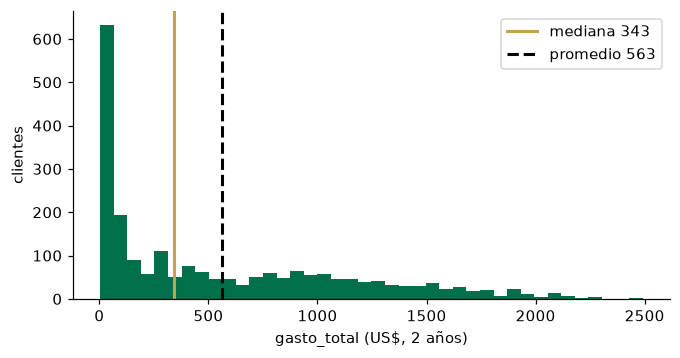

In [3]:
g = df["gasto_total"]
print(g.describe().round(0).to_string())
print("asimetría:", round(g.skew(), 2))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(g, bins=40, color=GREEN)
ax.axvline(g.median(), color=GOLD, lw=2, label=f"mediana {g.median():.0f}")
ax.axvline(g.mean(), color="black", lw=2, ls="--", label=f"promedio {g.mean():.0f}")
ax.set(xlabel="gasto_total (US$, 2 años)", ylabel="clientes"); ax.legend(); plt.show()

**Hallazgo.** `gasto_total` es asimétrico a la derecha: muchos clientes gastan poco y pocos gastan mucho. Por eso el promedio (563) queda por encima de la mediana (343). El promedio sobrestima al cliente típico y no sirve como único resumen.

## Parte 2 · k-means

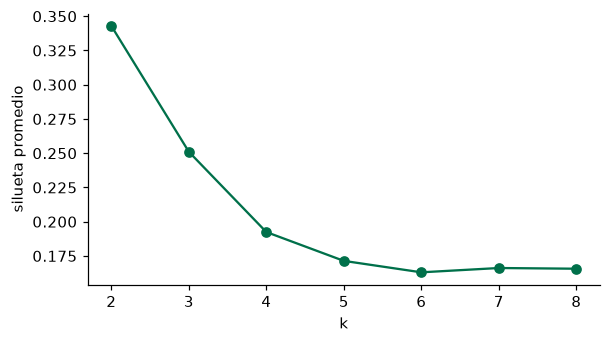

,2,3,4,5,6,7,8
silueta,0.343,0.251,0.192,0.171,0.163,0.166,0.166


In [4]:
cols = ["ingreso_anual", "gasto_total", "compras_tienda", "compras_web", "compras_catalogo",
        "visitas_web_mes", "recencia_dias", "hijos_pequenos", "edad"]
X = StandardScaler().fit_transform(df[cols])

ks = range(2, 9)
sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in ks]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(list(ks), sil, marker="o", color=GREEN)
ax.set(xlabel="k", ylabel="silueta promedio"); plt.show()
pd.Series(sil, index=list(ks), name="silueta").round(3).to_frame().T

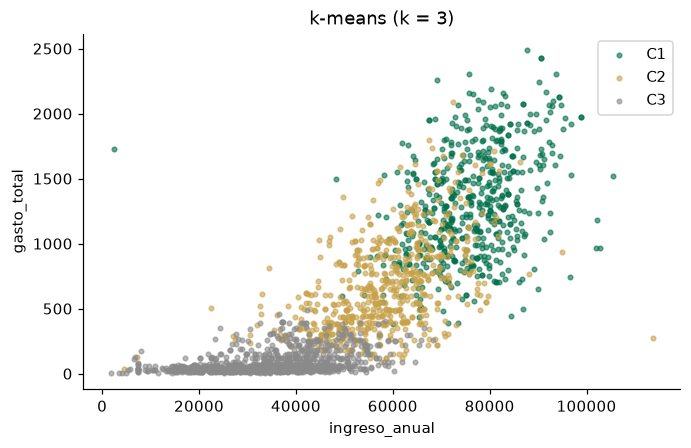

,clientes,ingreso_anual,gasto_total,compras_tienda,compras_web,compras_catalogo,visitas_web_mes,recencia_dias,hijos_pequenos,edad,respondio_ultima_campana
Cluster,,,,,,,,,,,
C1,561,76116.10,1303.74,8.59,4.89,6.19,2.63,52.12,0.03,51.79,0.25
C2,631,58158.72,670.37,7.55,6.47,2.84,5.71,46.12,0.17,55.84,0.14
C3,1013,33985.62,85.39,3.21,2.19,0.56,6.60,49.09,0.84,47.75,0.10


In [5]:
km = KMeans(3, n_init=10, random_state=0).fit(X)
orden = df.assign(c=km.labels_).groupby("c")["gasto_total"].mean().sort_values(ascending=False).index
etiqueta = {c: f"C{i + 1}" for i, c in enumerate(orden)}
df["Cluster"] = pd.Series(km.labels_).map(etiqueta)

colores = {"C1": GREEN, "C2": GOLD, "C3": "#8A8A8A"}
fig, ax = plt.subplots(figsize=(7, 4.2))
for c, sub in df.groupby("Cluster"):
    ax.scatter(sub["ingreso_anual"], sub["gasto_total"], s=9, alpha=.6, color=colores[c], label=c)
ax.set(xlabel="ingreso_anual", ylabel="gasto_total", title="k-means (k = 3)"); ax.legend(); plt.show()

perfil = df.groupby("Cluster")[cols + ["respondio_ultima_campana"]].mean().round(2)
perfil.insert(0, "clientes", df["Cluster"].value_counts().sort_index())
perfil

**Respuestas.**
- **Mejor k:** k = 2 (silueta 0.343). Con k = 3 baja a 0.251 y de ahí en adelante ronda 0.17. Ninguna es alta (todas por debajo de 0.5): los clientes forman un continuo y no grupos bien separados.
- **Por qué k = 3 igual:** marketing necesita más de dos grupos para actuar, y k = 3 separa un grupo de alto valor.
- **C1 · Compradores premium** (561): ingreso ≈76 mil, gasto ≈1,304, compran mucho en tienda y catálogo, casi sin hijos pequeños.
- **C2 · Clientes medios** (631): ingreso ≈58 mil, gasto ≈670, los de mayor edad y compras sólidas en tienda.
- **C3 · Bajo gasto con hijos** (1,013): ingreso ≈34 mil, gasto ≈85, muchas visitas a la web pero pocas compras, y casi todos con hijos pequeños.

## Parte 3 · Comparar técnicas

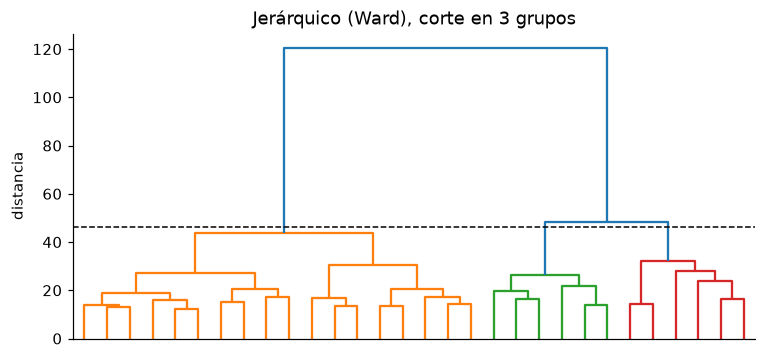

Jerarquico
1    980
2    372
3    853


In [6]:
Z = linkage(X, method="ward")
corte = (Z[-3, 2] + Z[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(8, 3.6))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=corte, ax=ax)
ax.axhline(corte, color="black", ls="--", lw=1)
ax.set(title="Jerárquico (Ward), corte en 3 grupos", ylabel="distancia"); plt.show()
df["Jerarquico"] = fcluster(Z, 3, criterion="maxclust")
print(df["Jerarquico"].value_counts().sort_index().to_string())

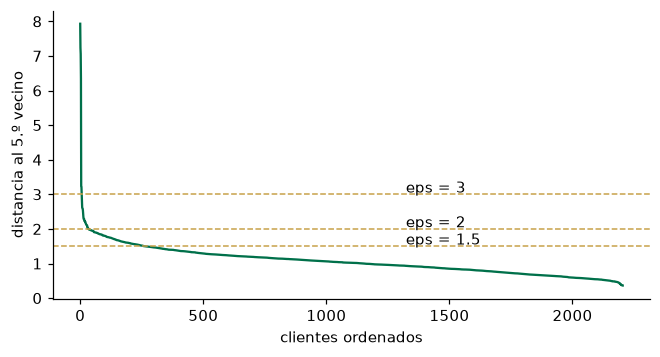

,grupos,ruido,tamaños
eps = 1.5,3,143,"[1186, 839, 37]"
eps = 2,1,19,[2186]
eps = 3,1,4,[2201]


In [7]:
k = 5
d5 = np.sort(NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)[0][:, -1])[::-1]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(d5, color=GREEN)
for e in (1.5, 2, 3):
    ax.axhline(e, color=GOLD, ls="--", lw=1); ax.text(len(d5) * .6, e + .05, f"eps = {e}")
ax.set(xlabel="clientes ordenados", ylabel=f"distancia al {k}.º vecino"); plt.show()

filas = {}
for eps in (1.5, 2, 3):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    filas[f"eps = {eps}"] = {"grupos": len(set(lab) - {-1}), "ruido": int((lab == -1).sum()),
                             "tamaños": sorted(pd.Series(lab[lab != -1]).value_counts().tolist(), reverse=True)}
df["DBSCAN"] = DBSCAN(eps=1.5, min_samples=5).fit_predict(X)
pd.DataFrame(filas).T

In [8]:
print("k-means vs jerárquico"); display(pd.crosstab(df["Cluster"], df["Jerarquico"]))
print("k-means vs DBSCAN (eps 1.5, -1 = ruido)"); display(pd.crosstab(df["Cluster"], df["DBSCAN"]))

k-means vs jerárquico


Jerarquico,1,2,3
Cluster,,,
C1,560,1,0
C2,409,164,58
C3,11,207,795


k-means vs DBSCAN (eps 1.5, -1 = ruido)


DBSCAN,-1,0,1,2
Cluster,,,,
C1,65,1,495,0
C2,63,76,492,0
C3,15,762,199,37


**Respuestas.**
- **¿Mismos grupos?** No del todo. k-means y Ward son parecidos en C1 (560 de 561 clientes coinciden), pero reparten distinto a los grupos medio y bajo (Ward: 980 / 372 / 853 clientes; k-means: 561 / 631 / 1,013). DBSCAN con eps = 1.5 da 3 grupos con 1,186 / 839 / 37 clientes y 143 de ruido.
- **Al subir eps:** DBSCAN junta todo. Con eps = 2 queda un solo grupo de 2,186 clientes y 19 de ruido; con eps = 3, un grupo de 2,201 y 4 de ruido. Los clientes forman una nube continua, sin huecos de baja densidad, y DBSCAN no encuentra fronteras.
- **El más útil para marketing:** k-means. Da exactamente 3 grupos de buen tamaño, con perfiles claros y fáciles de explicar.

**Evaluación de los cinco criterios** (sí / parcial / no):

| Técnica | Medible | Diferenciable | Accionable | Rentable | Estable | Nº de grupos y ruido |
|---|---|---|---|---|---|---|
| k-means (k = 3) | Sí | Sí | Sí | Sí | Parcial (depende de la semilla) | 3 grupos, 0 ruido |
| Jerárquico (Ward, 3) | Sí | Sí | Parcial | Sí | Parcial (cambia al agregar clientes) | 3 grupos, 0 ruido |
| DBSCAN (eps = 1.5) | Sí | Parcial | No | Parcial (un grupo de 37 clientes) | No (muy sensible a eps) | 3 grupos, 143 de ruido |

**Recomendación:** k-means. DBSCAN no sirve para estos clientes: con eps = 1.5 deja 143 clientes sin segmento, y con eps ≥ 2 devuelve un solo grupo.

## Parte 4 · ¿Cuánto vale cada segmento?

,clientes,pct_clientes,gasto_medio,pct_gasto,pct_respondio
Cluster,,,,,
C1,561,25.4,1303.7,58.9,25.3
C2,631,28.6,670.4,34.1,13.8
C3,1013,45.9,85.4,7.0,10.3


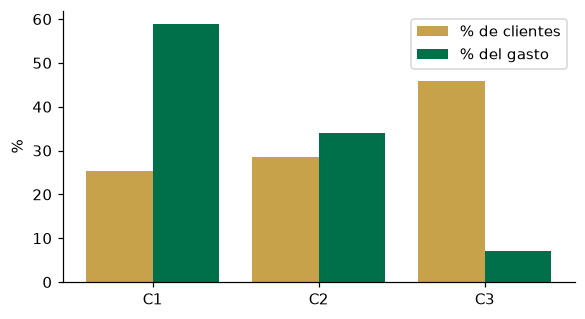

,margen (20% del gasto medio),costo campaña,margen / costo
Cluster,,,
C1,260.7,10,26.1
C2,134.1,10,13.4
C3,17.1,10,1.7


In [9]:
v = df.groupby("Cluster").agg(clientes=("gasto_total", "size"), gasto_medio=("gasto_total", "mean"),
                              gasto_total=("gasto_total", "sum"), respondio=("respondio_ultima_campana", "mean"))
v["pct_clientes"] = v["clientes"] / v["clientes"].sum() * 100
v["pct_gasto"] = v["gasto_total"] / v["gasto_total"].sum() * 100
v["pct_respondio"] = v["respondio"] * 100
v = v[["clientes", "pct_clientes", "gasto_medio", "pct_gasto", "pct_respondio"]].round(1)
display(v)

fig, ax = plt.subplots(figsize=(6, 3.2))
x = np.arange(3)
ax.bar(x - .2, v["pct_clientes"], .4, color=GOLD, label="% de clientes")
ax.bar(x + .2, v["pct_gasto"], .4, color=GREEN, label="% del gasto")
ax.set_xticks(x, v.index); ax.set_ylabel("%"); ax.legend(); plt.show()

margen = 0.20 * v["gasto_medio"]
pd.DataFrame({"margen (20% del gasto medio)": margen.round(1), "costo campaña": 10,
              "margen / costo": (margen / 10).round(1)})

In [10]:
df[["id_cliente", "Cluster"]].to_csv("clientes_con_cluster.csv", index=False)
pd.read_csv("clientes_con_cluster.csv")["Cluster"].value_counts().sort_index()

Cluster
C1     561
C2     631
C3    1013
Name: count, dtype: int64

**Respuestas.**
- **Concentración:** C1 es el 25% de los clientes y genera el 59% del gasto. C3 es el 46% de los clientes y solo el 7% del gasto.
- **Presupuesto de la próxima campaña:** a C1, y en segundo lugar a C2. C1 gasta ≈1,304 por cliente (margen de ≈261 con 20%, 26 veces el costo de US$10), aunque solo el 25% respondió la última campaña. C3 deja un margen de ≈17, apenas 1.7 veces el costo, y responde el 10%.
- **Acción por segmento:** C1 retener (CLV alto, perder uno cuesta mucho). C2 crecer (cruzar con más categorías y catálogo). C3 no invertir en campañas de pago; mantener canales baratos como el correo o la web, porque en el CLV/CAC un CAC de US$10 sobre ≈17 de margen casi no deja ganancia.
- **Archivo:** `clientes_con_cluster.csv` con la columna `Cluster` (C1, C2, C3) para la tarea.

## Parte 5 · Datos sintéticos: cuando k-means falla

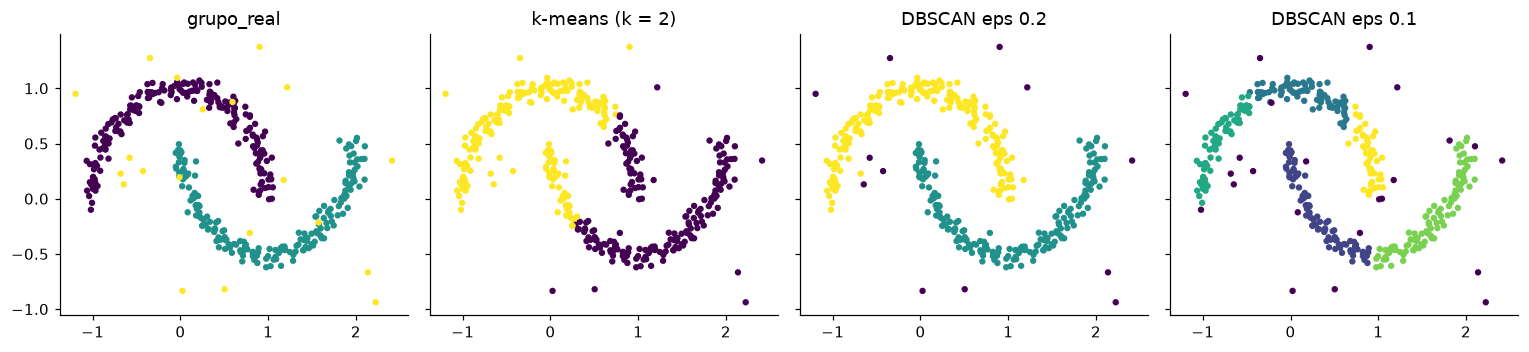

k-means k=2


col_0,0,1
grupo_real,,
luna_A,49,151
luna_B,150,50
ruido,9,11


DBSCAN eps 0.2


col_0,-1,0,1
grupo_real,,,
luna_A,0,0,200
luna_B,0,200,0
ruido,12,3,5


DBSCAN eps 0.1


col_0,-1,0,1,2,3,4
grupo_real,,,,,,
luna_A,4,0,76,71,0,49
luna_B,4,94,0,0,102,0
ruido,15,1,3,0,1,0


In [11]:
lu = leer("formas_lunas.csv")
Y = lu[["x", "y"]].values
km2 = KMeans(2, n_init=10, random_state=0).fit_predict(Y)
db2, db1 = DBSCAN(eps=.2, min_samples=5).fit_predict(Y), DBSCAN(eps=.1, min_samples=5).fit_predict(Y)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.3), sharex=True, sharey=True)
real = lu["grupo_real"].astype("category").cat.codes
for ax, lab, t in zip(axs, [real, km2, db2, db1], ["grupo_real", "k-means (k = 2)", "DBSCAN eps 0.2", "DBSCAN eps 0.1"]):
    ax.scatter(Y[:, 0], Y[:, 1], c=lab, cmap="viridis", s=10); ax.set_title(t)
plt.tight_layout(); plt.show()

for t, lab in [("k-means k=2", km2), ("DBSCAN eps 0.2", db2), ("DBSCAN eps 0.1", db1)]:
    print(t); display(pd.crosstab(lu["grupo_real"], lab))

**Respuestas.**
- **Por qué k-means corta mal:** k-means arma grupos redondos alrededor de un centro y corta con una línea recta entre centros. Las lunas son curvas y se enroscan, así que mezcla ≈50 puntos de cada luna en el grupo equivocado.
- **DBSCAN:** con eps = 0.2 separa las dos lunas sin error (200 y 200) y marca 12 de los 20 puntos de ruido como ruido; con eps = 0.1 rompe cada luna en varios pedazos y ve más ruido (23 puntos).
- **Cuándo sospechar de clientes sin forma de bolas:** cuando la silueta es baja, los grupos de k-means quedan muy desiguales o el gráfico muestra formas alargadas o curvas.

**Pregunta 11.** En las lunas, hay huecos claros de baja densidad entre los grupos y DBSCAN los aprovecha. En los clientes reales no hay huecos: la nube es continua, y al subir eps DBSCAN junta todo en un solo grupo. A un gerente que pide «la técnica más moderna» se le diría que la mejor técnica es la que se ajusta a la forma de los datos y produce grupos sobre los que se puede actuar. Aquí es k-means.

## Riesgos y cierre

**Pregunta 12 (riesgos).** Segmentar por edad, hijos o estado civil es válido para entender el negocio, pero no para negar un servicio, subir precios o excluir a un grupo, porque eso discrimina. El límite está en que el segmento no decida sobre condiciones básicas ni infiera datos sensibles. Hay que usar solo datos que el cliente aceptó compartir, y revisar que ningún segmento quede definido por un atributo protegido.

**Pregunta 13 (cambio en el tiempo).** Conviene recalcular cada trimestre, o antes si hay una campaña grande o un cambio de precios. Señales a vigilar: cambios en el tamaño de cada segmento, clientes que cambian de grupo, caída de la recencia en C1 y baja de la respuesta a campañas.

**Conclusión (3 líneas).** Se recomienda segmentar con k-means (k = 3) sobre variables estandarizadas, porque produce tres grupos claros y accionables, mientras que DBSCAN no encuentra estructura en estos clientes. El segmento de mayor valor (C1: 25% de los clientes, 59% del gasto) debe recibir el presupuesto de retención y venta cruzada. Para C3 conviene usar solo canales de bajo costo.